In [6]:
from metpy.plots import SkewT
import metpy.calc
from metpy.units import units
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'

In [7]:
# Dropsonde
dropsondeFile = RAW_DATA / 'CAMP2Ex_Dropsonde' / 'CAMP2EX-dropsondes_P3B_20191002022856_R0.nc'
dropsonde = xr.load_dataset(dropsondeFile)

cond_pres = np.logical_not(np.isnan(dropsonde.pres.data))
cond_tdry = np.logical_not(np.isnan(dropsonde.tdry.data))
cond_gpsalt = np.logical_not(np.isnan(dropsonde.gpsalt.data))
cond = cond_pres & cond_tdry & cond_gpsalt

p_ds = dropsonde.pres.data[cond]
T_ds = dropsonde.tdry.data[cond]
Td_ds = dropsonde.dp.data[cond]
u_ds = dropsonde.u_wind.data[cond]
v_ds = dropsonde.v_wind.data[cond]

In [8]:
interp_time = np.datetime64('2019-10-02T02:33:00')
interp_lat = 19.6
interp_lon = 120.75

In [9]:
era_surf_file = RAW_DATA / 'era5' / 'ERA5_surface_CAMP2Ex_RF17_wide_extra.nc'
era_surf = xr.load_dataset(era_surf_file)
era_surf_interp = era_surf.interp(
    valid_time=interp_time,
    latitude = interp_lat,
    longitude = interp_lon
)

In [10]:
era_upper_file = RAW_DATA / 'era5' / 'ERA5_upper_CAMP2Ex_RF17_wide.nc'
era_upper = xr.load_dataset(era_upper_file)
era_upper_interp = era_upper.interp(
    valid_time=interp_time,
    latitude = interp_lat,
    longitude = interp_lon
)

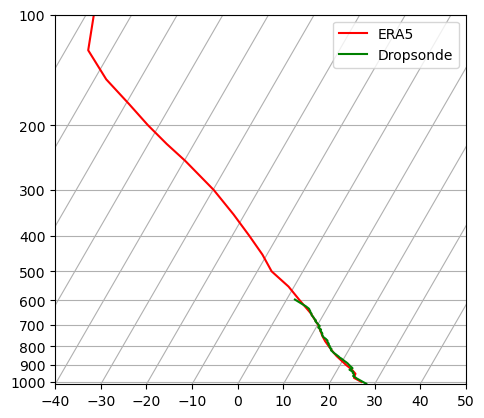

In [11]:
skew = SkewT()
skew.plot(era_upper_interp.pressure_level.data, era_upper_interp.t.data-273.15, 'r', label='ERA5')
skew.plot(p_ds, T_ds, 'g', label='Dropsonde')
skew.ax.set_ylim(1015, 100)
plt.legend()

Text(0.5, 1.0, 'ERA5')

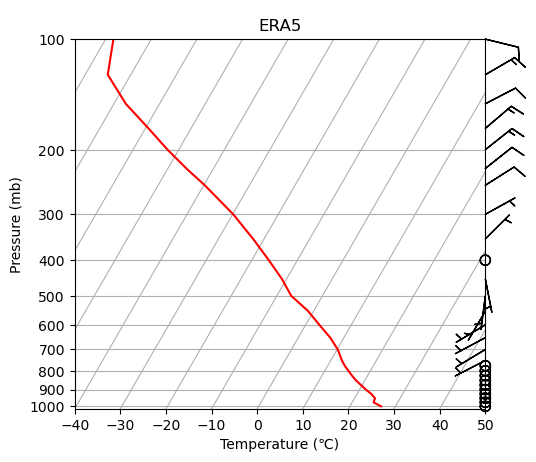

In [12]:
skew = SkewT()

skew.plot(era_upper_interp.pressure_level.data, era_upper_interp.t.data-273.15, 'r')
skew.plot_barbs(era_upper_interp.pressure_level.data, era_upper_interp.u.data, era_upper_interp.v.data)

skew.ax.set_xlabel('Temperature (\N{DEGREE CELSIUS})')
skew.ax.set_ylabel('Pressure (mb)')

skew.ax.set_ylim(1015, 100)

skew.ax.set_title('ERA5')

Text(0.5, 1.0, 'CAMP2Ex Dropsonde')

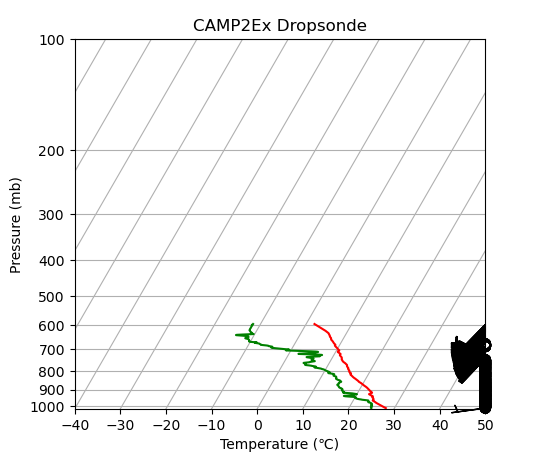

In [13]:
skew = SkewT()

skew.plot(p_ds, T_ds, 'r')
skew.plot(p_ds, Td_ds, 'g')
skew.plot_barbs(p_ds, u_ds, v_ds)

skew.ax.set_xlabel('Temperature (\N{DEGREE CELSIUS})')
skew.ax.set_ylabel('Pressure (mb)')

skew.ax.set_ylim(1015, 100)

skew.ax.set_title('CAMP2Ex Dropsonde')

In [14]:
era_upper

<xarray.Dataset> Size: 4MB
Dimensions:         (valid_time: 5, pressure_level: 37, latitude: 17,
                     longitude: 21)
Coordinates:
    number          int64 8B 0
  * valid_time      (valid_time) datetime64[ns] 40B 2019-10-02 ... 2019-10-02...
  * pressure_level  (pressure_level) float64 296B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude        (latitude) float64 136B 21.4 21.15 20.9 ... 17.9 17.65 17.4
  * longitude       (longitude) float64 168B 118.0 118.2 118.5 ... 122.8 123.0
    expver          (valid_time) <U4 80B '0001' '0001' '0001' '0001' '0001'
Data variables: (12/16)
    d               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    cc              (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    z               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    o3              (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    pv              (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    r               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    ...              ...
    cswc            (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    t               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    w               (valid_time, pressure_level, latitude, longitude) float32 264kB ...
    vo              (valid_time, pressure_level, latitude, longitude) float32 264kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-08-21T14:03 GRIB to CDM+CF via cfgrib-0.9.1...